# Pixel video model, T1

From scratch, no VAE: frame t (128x128) -> frame t+10, by flow matching with a small U-Net.
The oracle IDM (`idm.ipynb`, 19/20) then reads the 10 actions off the dreamed frame.


In [20]:
%load_ext autoreload
%autoreload 2
from notebook_cache import NotebookCache

cache = NotebookCache('../cache/video_nb')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Step 0: data

Same cache as `lam.ipynb` / `idm.ipynb`: top-camera frames, joints, actions, demo ids.


In [21]:
import numpy as np
from uwm_parts import load_table

NAME = 'pick_place_cube_n100'
state, action, episode = load_table(NAME)
top = np.load(f'../cache/lam/{NAME}_top.npy')  # [N, 3, 128, 128] uint8
print(f'{top.shape=}  demos {episode.max() + 1}')

top.shape=(21295, 3, 128, 128)  demos 100


## Step 1: pairs

Row t = (frame t, frame t+10), both in the same demo. Val = the same 10 demos as `idm.ipynb`.


In [22]:
K = 10  # frames ahead
ok = np.flatnonzero(episode[:-K] == episode[K:])  # rows t with t+10 in the same demo
val = np.random.default_rng(0).permutation(100)[:10]
tr, r = ok[~np.isin(episode[ok], val)], ok[np.isin(episode[ok], val)]
print(len(tr), 'train pairs ', len(r), 'val pairs')

18256 train pairs  2039 val pairs


Baseline: copy frame t as the guess for t+10. Pixel MSE on val, pixels in [0, 1].


In [23]:
now, fut = top[r] / np.float32(255), top[r + K] / np.float32(255)
print(f'copy  mse {((now - fut) ** 2).mean():.5f}')

copy  mse 0.01320


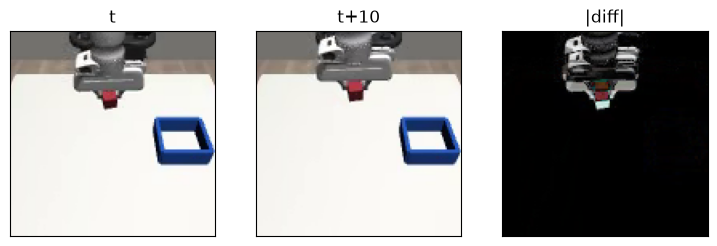

In [24]:
import matplotlib.pyplot as plt

i = 300  # one val pair
fig, axs = plt.subplots(1, 3, figsize=(9, 3))
for ax, img, name in zip(axs, [now[i], fut[i], abs(fut[i] - now[i])], ['t', f't+{K}', '|diff|']):
    ax.imshow(img.transpose(1, 2, 0))
    ax.set(xticks=[], yticks=[])
    ax.set_title(name)

## Step 2: the U-Net, piece by piece

Input = frame t (3 ch) stacked with the noisy future frame (3 ch); denoising turns it into [t, t+10], pixels in [-1, 1].


In [140]:
import torch
from torch import nn

dev = 'cuda'


def frames(rows, cam=None):
    # uint8 [B, 3, 128, 128] -> float in [-1, 1] on the GPU; cam: the camera array (default top)
    return torch.tensor((top if cam is None else cam)[rows], device=dev).float() / 127.5 - 1


x = torch.cat([frames(r[:4]), torch.randn(4, 3, 128, 128, device=dev)], 1)  # [now, noisy future]
print(x.shape)

torch.Size([4, 6, 128, 128])


In [26]:
def down(i, o):
    # halves height and width
    return nn.Sequential(nn.Conv2d(i, o, 3, stride=2, padding=1), nn.GroupNorm(8, o), nn.SiLU())


down1 = down(6, 64).to(dev)
print(down1(x).shape)

torch.Size([4, 64, 64, 64])


In [27]:
down2, down3 = down(64, 128).to(dev), down(128, 256).to(dev)
h1 = down1(x)
h2 = down2(h1)
h3 = down3(h2)
print(h1.shape, h2.shape, h3.shape, sep='\n')

torch.Size([4, 64, 64, 64])
torch.Size([4, 128, 32, 32])
torch.Size([4, 256, 16, 16])


In [28]:
def up(i, o):
    # doubles height and width
    return nn.Sequential(
        nn.Upsample(scale_factor=2), nn.Conv2d(i, o, 3, padding=1), nn.GroupNorm(8, o), nn.SiLU()
    )


up3 = up(256, 128).to(dev)
print(up3(h3).shape)

torch.Size([4, 128, 32, 32])


In [29]:
up2 = up(128 + 128, 64).to(dev)  # input: up3's output joined with the skip h2
u2 = up2(torch.cat([up3(h3), h2], 1))
print(u2.shape)

torch.Size([4, 64, 64, 64])


In [30]:
up1 = up(64 + 64, 64).to(dev)  # u2 joined with the skip h1
u1 = up1(torch.cat([u2, h1], 1))
print(u1.shape)

torch.Size([4, 64, 128, 128])


In [31]:
out = nn.Conv2d(64, 3, 1).to(dev)  # velocity of the future frame only
print(out(u1).shape)

torch.Size([4, 3, 128, 128])


Flow time τ in [0, 1] (0 = noise, 1 = clean): sin/cos at 32 frequencies, then an MLP to 256 numbers,
added to every cell of the 16x16 map.


In [32]:
def tau_feats(tau):
    # [B] -> [B, 64]
    f = tau[:, None] * torch.exp(torch.linspace(0, 7, 32, device=dev))  # frequencies 1..~1100
    return torch.cat([f.sin(), f.cos()], 1)


tau = torch.rand(4, device=dev)
print(tau_feats(tau).shape)

torch.Size([4, 64])


In [33]:
temb = nn.Sequential(nn.Linear(64, 256), nn.SiLU(), nn.Linear(256, 256)).to(dev)
h3t = h3 + temb(tau_feats(tau))[:, :, None, None]  # [4, 256] -> [4, 256, 1, 1] broadcast over 16x16
print(h3t.shape)

torch.Size([4, 256, 16, 16])


## Step 3: pack into a class

Step 2's loose pieces as one `UNet`; the same weights must give the same output.


In [160]:
class UNet(nn.Module):
    # [condition frames, noisy future] + tau -> the net's output for the future frame
    def __init__(self, cond=3, out=3):  # cond: channels of condition frames (3 = frame t only)
        # out: channels of the future frame (3 = top; 6 = top + wrist)
        super().__init__()
        self.down1, self.down2, self.down3 = down(cond + out, 64), down(64, 128), down(128, 256)
        self.temb = nn.Sequential(nn.Linear(64, 256), nn.SiLU(), nn.Linear(256, 256))
        self.up3, self.up2, self.up1 = up(256, 128), up(128 + 128, 64), up(64 + 64, 64)
        self.out = nn.Conv2d(64, out, 1)

    def forward(self, now, noisy, tau):
        h1 = self.down1(torch.cat([now, noisy], 1))
        h2 = self.down2(h1)
        h3 = self.down3(h2) + self.temb(tau_feats(tau))[:, :, None, None]
        u2 = self.up2(torch.cat([self.up3(h3), h2], 1))
        return self.out(self.up1(torch.cat([u2, h1], 1)))

In [35]:
packed = UNet().to(dev)
for name in ['down1', 'down2', 'down3', 'temb', 'up3', 'up2', 'up1', 'out']:
    getattr(packed, name).load_state_dict(globals()[name].state_dict())
with torch.no_grad():
    loose = out(up1(torch.cat([up2(torch.cat([up3(h3t), h2], 1)), h1], 1)))
    diff = (packed(x[:, :3], x[:, 3:], tau) - loose).abs().max()
print(f'max diff vs loose pieces: {diff.item()}')
print(f'{sum(p.numel() for p in packed.parameters()) / 1e6:.2f}M params')

max diff vs loose pieces: 0.0
0.97M params


## Step 4: the flow-matching loss

```-
noisy  = (1 - τ)·noise + τ·future
target = future - noise        (d noisy / d τ)
loss   = mse(net(now, noisy, τ), target)
```


In [36]:
rows = np.random.default_rng(0).choice(tr, 32)
f_now, f_fut = frames(rows), frames(rows + K)
noise, tau = torch.randn_like(f_fut), torch.rand(32, device=dev)
noisy = (1 - tau[:, None, None, None]) * noise + tau[:, None, None, None] * f_fut
with torch.no_grad():
    loss = ((packed(f_now, noisy, tau) - (f_fut - noise)) ** 2).mean()
print(f'untrained loss {loss.item():.3f}')

untrained loss 1.861


## Step 5: train

Every 1000 steps: the loss on 512 val pairs, with noise and τ fixed so the number is comparable
across steps (untrained: 1.661 on a train batch).


In [141]:
first = np.searchsorted(episode, episode)  # each row's demo start


def cond(rows, past=False, n_past=1, gap=K, cam=None):
    # frame t [B, 3, 128, 128], or with past: [frame t-n_past*gap, ..., frame t-gap, frame t] [B, 3 + 3 n_past, ...]
    # (past rows clamped to the demo's first frame, as a rollout's start would be)
    back = [np.maximum(rows - j * gap, first[rows]) for j in range(n_past if past else 0, 0, -1)]
    return torch.cat([frames(b, cam) for b in back] + [frames(rows, cam)], 1)

In [161]:
from frozendict import frozendict


@cache(keep=True)
def train_video(
    steps: int = 10000,
    B: int = 32,
    lr: float = 3e-4,
    seed: int = 0,
    predict: str = 'v',
    past: bool = False,
    n_past: int = 1,
    upweight: float = 0.0,
    wrist: bool = False,
):
    # a fresh UNet on (frame t, frame t+K) -> weights (CPU), log rows [step, train loss, val loss]
    # predict: 'v' = velocity (future - noise), 'x' = the clean future frame
    # past: also condition on n_past earlier frames, K apart (t-K, t-2K, ...)
    # wrist: condition on and dream [top, wrist] (6 channels each)
    # upweight: sample rows with prob ∝ 1 + upweight * change / mean change (step 15's `change`)
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    cams = [None, wcam] if wrist else [None]  # None = top
    net = UNet((3 + 3 * n_past if past else 3) * len(cams), 3 * len(cams)).to(dev)

    def condition(rows):
        return torch.cat([cond(rows, past, n_past, cam=c) for c in cams], 1)

    def future(rows):
        return torch.cat([frames(rows + K, c) for c in cams], 1)

    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(r, 512, replace=False)
    g = torch.Generator(device=dev).manual_seed(1)
    v_noise = torch.randn(512, 3 * len(cams), 128, 128, device=dev, generator=g)
    v_tau = torch.rand(512, device=dev, generator=g)
    p = (w := 1 + upweight * change / change.mean()) / w.sum() if upweight else None
    log = []
    for step in range(1, steps + 1):
        b = rng.choice(tr, B, p=p)
        now, fut = condition(b), future(b)
        noise, tau = torch.randn_like(fut), torch.rand(B, device=dev)
        tw = tau[:, None, None, None]
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss = (
                (
                    net(now, (1 - tw) * noise + tw * fut, tau).float()
                    - (fut if predict == 'x' else fut - noise)
                )
                .square()
                .mean()
            )
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step % 1000 == 0:
            vl = 0.0
            with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                for i in range(0, 512, 64):
                    now, fut = condition(vr[i : i + 64]), future(vr[i : i + 64])
                    n, t = v_noise[i : i + 64], v_tau[i : i + 64]
                    tw = t[:, None, None, None]
                    pred = net(now, (1 - tw) * n + tw * fut, t).float()
                    vl += (pred - (fut if predict == 'x' else fut - n)).square().mean().item() / 8
            log.append([step, loss.item(), vl])
            print(f'{step:5d}  train {loss.item():.4f}   val {vl:.4f}', flush=True)
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_video: not cached, will compute (or replay older code's result: keep)


In [38]:
run = train_video()

train_video: result copied by keep=True from older code (cell d4cdea37486d)
 1000  train 0.3036   val 0.2849
 2000  train 0.2103   val 0.2136
 3000  train 0.1941   val 0.1917
 4000  train 0.2105   val 0.1787
 5000  train 0.1988   val 0.1661
 6000  train 0.1912   val 0.1583
 7000  train 0.2324   val 0.1509
 8000  train 0.1580   val 0.1472
 9000  train 0.1407   val 0.1453
10000  train 0.1447   val 0.1448


## Step 6: dream

Euler steps from noise (τ=0) to the frame (τ=1), following the net's velocity.


In [162]:
net_v = UNet().to(dev).eval()
net_v.load_state_dict(run['weights'])


@torch.no_grad()
def dream(net, now, predict='v', n=20, seed=0):
    # condition frames [B, 3+, 128, 128] in [-1, 1] -> dreamed frame t+K [B, 3 or 6, ...], n Euler steps
    # predict: what the net outputs, 'v' velocity or 'x' the clean frame
    x = torch.randn(
        (len(now), net.out.out_channels, 128, 128),
        device=dev,
        generator=torch.Generator(device=dev).manual_seed(seed),
    )
    for i in range(n):
        tau = i / n
        out = net(now, x, torch.full((len(now),), tau, device=dev))
        x = x + (out if predict == 'v' else (out - x) / (1 - tau)) / n
    return x.clamp(-1, 1)

In [46]:
vr = np.random.default_rng(1).choice(r, 512, replace=False)
err = [
    ((dream(net_v, frames(b)) - frames(b + K)) / 2).square().mean().item() for b in np.split(vr, 8)
]
print(f'dream mse {np.mean(err):.5f}   (copy frame t: 0.01320)')

dream mse 0.02100   (copy frame t: 0.01320)


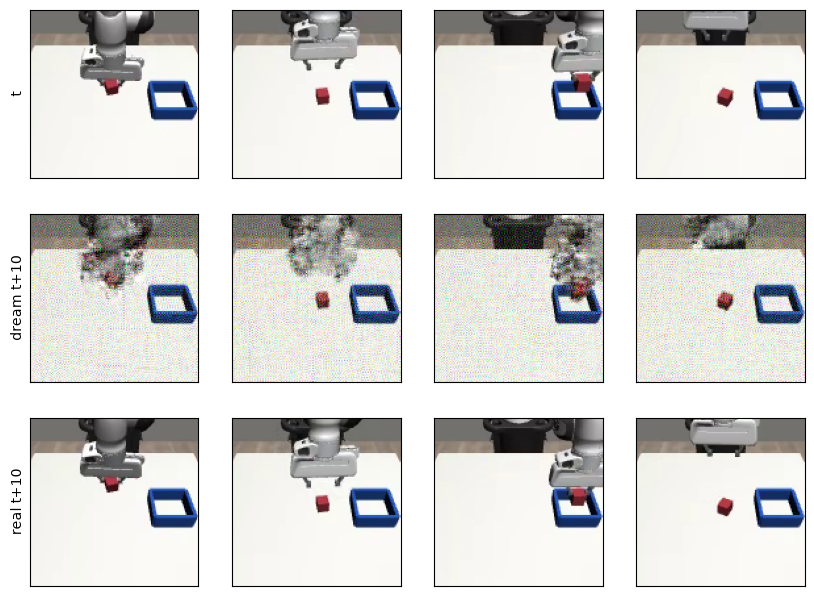

In [41]:
b = vr[:4]
strip = [frames(b), dream(net_v, frames(b)), frames(b + K)]
fig, axs = plt.subplots(3, 4, figsize=(10, 7.5))
for row, imgs, name in zip(axs, strip, ['t', 'dream t+10', 'real t+10']):
    row[0].set_ylabel(name)
    for ax, img in zip(row, imgs):
        ax.imshow((img.cpu().numpy().transpose(1, 2, 0) + 1) / 2)
        ax.set(xticks=[], yticks=[])

In [42]:
for n in [20, 50]:
    err = [
        ((dream(net_v, frames(b), n=n) - frames(b + K)) / 2).square().mean().item()
        for b in np.split(vr, 8)
    ]
    print(f'{n} steps: dream mse {np.mean(err):.5f}')

20 steps: dream mse 0.02100
50 steps: dream mse 0.02133


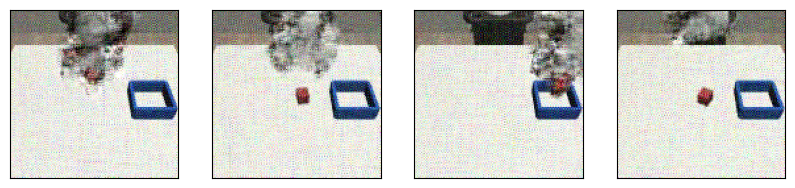

In [43]:
fig, axs = plt.subplots(1, 4, figsize=(10, 2.5))
for ax, img in zip(axs, dream(net_v, frames(vr[:4]), n=50)):
    ax.imshow((img.cpu().numpy().transpose(1, 2, 0) + 1) / 2)
    ax.set(xticks=[], yticks=[])

## Step 7: predict the clean frame

Same net, target = frame t+10 itself. Sampling turns it back into a velocity:

```-
v = (x̂ - noisy) / (1 - τ)
```


In [44]:
run_x = train_video(predict='x')

 1000  train 0.0102   val 0.0096
 2000  train 0.0065   val 0.0074
 3000  train 0.0049   val 0.0066
 4000  train 0.0066   val 0.0058
 5000  train 0.0063   val 0.0053
 6000  train 0.0046   val 0.0051
 7000  train 0.0043   val 0.0049
 8000  train 0.0043   val 0.0046
 9000  train 0.0034   val 0.0045
10000  train 0.0043   val 0.0045


In [47]:
net_x = UNet().to(dev).eval()
net_x.load_state_dict(run_x['weights'])
err = [
    ((dream(net_x, frames(b), 'x') - frames(b + K)) / 2).square().mean().item()
    for b in np.split(vr, 8)
]
print(f'x dream mse {np.mean(err):.5f}   (v: 0.02100, copy frame t: 0.01320)')

x dream mse 0.00378   (v: 0.02100, copy frame t: 0.01320)


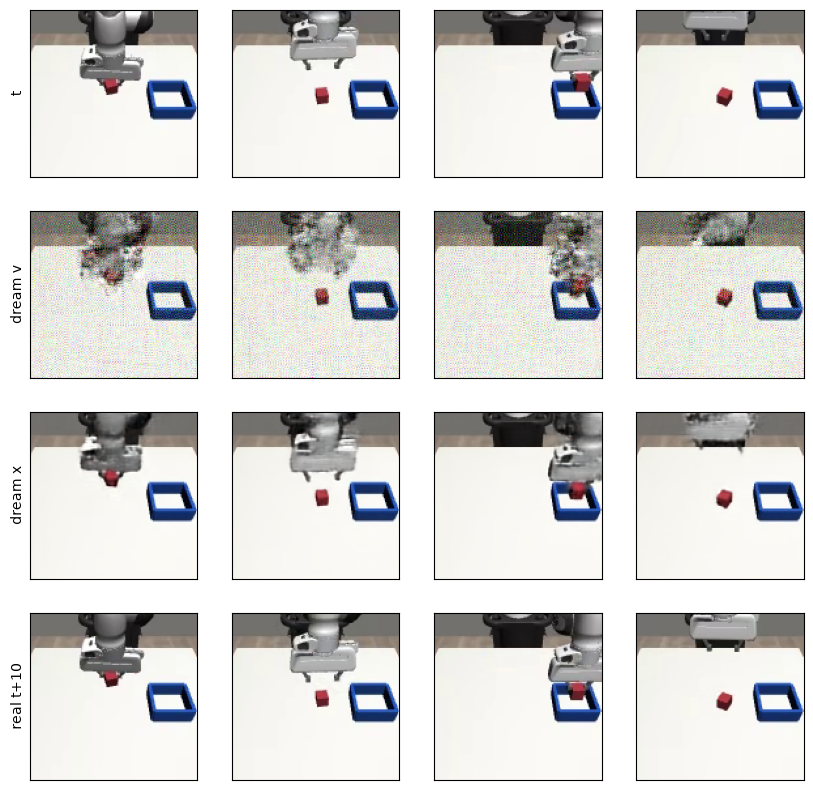

In [48]:
b = vr[:4]
strip = [frames(b), dream(net_v, frames(b)), dream(net_x, frames(b), 'x'), frames(b + K)]
fig, axs = plt.subplots(4, 4, figsize=(10, 10))
for row, imgs, name in zip(axs, strip, ['t', 'dream v', 'dream x', 'real t+10']):
    row[0].set_ylabel(name)
    for ax, img in zip(row, imgs):
        ax.imshow((img.cpu().numpy().transpose(1, 2, 0) + 1) / 2)
        ax.set(xticks=[], yticks=[])

## Step 8: the IDM reads the dreams

`idm.ipynb`'s trained IDM (19/20 with the real future) gets frame t + a guess of t+10.
Guesses: the real frame, the x dream, and frame t again (no motion at all).


In [142]:
from idm_parts import load_idm

idm = load_idm()
s_mean, s_std = state[tr].mean(0), state[tr].std(0)  # idm.ipynb's stats: same 90 train demos
a_mean, a_std = action[tr].mean(0), action[tr].std(0)

In [52]:
@torch.no_grad()
def read(rows, fut):
    # rows, a guess of frame t+K [B, 3, 128, 128] in [-1, 1] -> the IDM's actions [B, K, 8], joint units
    joints = torch.tensor((state[rows] - s_mean) / s_std, device=dev)
    return idm((frames(rows) + 1) / 2, (fut + 1) / 2, joints).cpu().numpy() * a_std + a_mean

In [53]:
preds = {'real': [], 'dream x': [], 'copy t': []}
for b in np.split(vr, 8):
    preds['real'].append(read(b, frames(b + K)))
    preds['dream x'].append(read(b, dream(net_x, frames(b), 'x')))
    preds['copy t'].append(read(b, frames(b)))
preds = {name: np.concatenate(p) for name, p in preds.items()}

In [54]:
chunk = action[vr[:, None] + np.arange(K)]  # [512, 10, 8]: the true actions
flips = (chunk[:, 1:, 7] != chunk[:, :-1, 7]).any(1)  # chunks where the gripper command changes
for name, p in preds.items():
    right = (p[..., 7] > 0.5) == (chunk[..., 7] > 0.5)
    print(
        f'{name:8s} arm {((p - chunk)[..., :7] ** 2).mean():.5f}   gripper right {right.mean():.1%}'
        f'   on {flips.sum()} flip chunks {right[flips].mean():.1%}'
    )

real     arm 0.00003   gripper right 99.5%   on 50 flip chunks 95.2%
dream x  arm 0.00024   gripper right 99.1%   on 50 flip chunks 92.8%
copy t   arm 0.00134   gripper right 96.2%   on 50 flip chunks 63.2%


## Step 9: closed loop

Every 10 steps: dream frame t+10 from the live camera frame, the IDM reads 10 actions, the
robot plays them. No expert, no rewind. Same 20 seeds as `idm.ipynb` (oracle future: 19/20).


In [55]:
from uwm_parts import make_sim

env = make_sim()

In [170]:
def to_t(img):
    # camera image [128, 128, 3] uint8 -> [1, 3, 128, 128] in [-1, 1] on the GPU
    return torch.tensor(img, device=dev).permute(2, 0, 1)[None].float() / 127.5 - 1


@torch.no_grad()
def plan(net, obs, prev=(), reader=None, wrist=False):
    # live observation (+ earlier camera images, oldest first, for a past=True net)
    # reader: the IDM (default: idm.ipynb's); one with n_past also reads the last n_past of prev
    # wrist: the net sees and dreams [top, wrist] (no past frames then); a top-only reader gets the top half
    # -> (10 actions [K, 8] in joint units, the dreamed frame t+10 [3 or 6, 128, 128])
    now = torch.cat([to_t(obs.images[c]) for c in (['top', 'wrist'] if wrist else ['top'])], 1)
    fut = dream(net, torch.cat([to_t(p) for p in prev] + [now], 1), 'x')
    joints = torch.tensor((obs.state - s_mean) / s_std, device=dev)[None]
    reader = reader or idm
    past = [(to_t(p) + 1) / 2 for p in prev[len(prev) - reader.n_past :]]
    views = 6 if getattr(reader, 'wrist', False) else 3
    acts = (
        reader((now[:, :views] + 1) / 2, (fut[:, :views] + 1) / 2, joints, past)[0].cpu().numpy()
        * a_std
        + a_mean
    )
    acts[:, 7] = acts[:, 7].clip(0, 1)
    return acts, fut[0]

In [164]:
def rollout(seed, net, past=False, gap=K, n_past=1, reader=None, wrist=False):
    # one episode driven by video model + IDM -> (success, failure mode, steps)
    # gap: spacing of the past=True net's earlier frames (K as trained; 0 = frame t repeated)
    obs = env.reset(seed=seed)
    seen = []  # camera images so far; before step K the first one stands in for t-K
    for t in range(600):
        seen.append(obs.images['top'])
        if t % K == 0:
            acts, _ = plan(
                net, obs, [seen[max(t - j * gap, 0)] for j in range(n_past if past else 0, 0, -1)],
                reader, wrist,
            )
        res = env.step(acts[t % K])
        obs = res.observation
        if res.terminated or res.truncated:
            break
    return res.success, str(res.failure_mode), t + 1

In [58]:
from collections import Counter

res = {seed: rollout(seed, net_x) for seed in range(1000, 1020)}
print(f'video model + IDM: {sum(s for s, _, _ in res.values())}/20   (oracle future: 19/20)')
print('failures', Counter(m for s, m, _ in res.values() if not s))

video model + IDM: 17/20   (oracle future: 19/20)
failures Counter({'wrong_target': 3})


In [61]:
failed = [seed for seed, (ok, _, _) in res.items() if not ok]
print(failed)

[1001, 1002, 1016]


Video of a failed seed: left the real camera, right the dream the current plan aims at.


In [171]:
def rollout_frames(seed, net, past=False, gap=K, n_past=1, reader=None, wrist=False):
    # rollout(), keeping every step's [real | current dream] per camera (top, then wrist), 2x upscaled
    obs = env.reset(seed=seed)
    seen, frames = [], []
    for t in range(600):
        seen.append(obs.images['top'])
        if t % K == 0:
            acts, fut = plan(
                net, obs, [seen[max(t - j * gap, 0)] for j in range(n_past if past else 0, 0, -1)],
                reader, wrist,
            )
            dreamed = (
                ((fut + 1) * 127.5).round().byte().permute(1, 2, 0).cpu().numpy()
            )  # [128, 128, 3 or 6]
        cams = ['top', 'wrist'] if wrist else ['top']
        pairs = [
            img
            for j, c in enumerate(cams)
            for img in (obs.images[c], dreamed[..., 3 * j : 3 * j + 3])
        ]
        frames.append(np.concatenate(pairs, 1).repeat(2, 0).repeat(2, 1))
        res = env.step(acts[t % K])
        obs = res.observation
        if res.terminated or res.truncated:
            break
    print(f'seed {seed}: {t + 1} steps, success {res.success}, {res.failure_mode}')
    return frames

In [63]:
import imageio
from IPython.display import Video

imageio.mimsave(f'../scratch/video_seed{failed[0]}.mp4', rollout_frames(failed[0], net_x), fps=20)
Video(f'../scratch/video_seed{failed[0]}.mp4', embed=True, width=512)

seed 1001: 600 steps, success False, wrong_target


In [64]:
imageio.mimsave('../scratch/video_seed1002.mp4', rollout_frames(1002, net_x), fps=20)
Video('../scratch/video_seed1002.mp4', embed=True, width=512)

seed 1002: 600 steps, success False, wrong_target


In [65]:
imageio.mimsave('../scratch/video_seed1016.mp4', rollout_frames(1016, net_x), fps=20)
Video('../scratch/video_seed1016.mp4', embed=True, width=512)

seed 1016: 600 steps, success False, wrong_target


In [66]:
imageio.mimsave('../scratch/video_seed1000.mp4', rollout_frames(1000, net_x), fps=20)  # a success
Video('../scratch/video_seed1000.mp4', embed=True, width=512)

seed 1000: 202 steps, success True, none


## Step 10: error where things move

Whole-frame MSE is mostly the static table. Score only pixels that change from t to t+10
(any channel by more than 0.05, pixels in [0, 1]): the arm, the fingers, the cube.


In [67]:
def moving_mse(guess, now, fut):
    # all [B, 3, 128, 128] in [-1, 1] -> (squared error summed over moving pixels, number of them)
    moving = ((fut - now).abs() / 2 > 0.05).any(1, keepdim=True).expand_as(fut)
    return (((guess - fut) / 2) ** 2)[moving].sum().item(), moving.sum().item()

In [68]:
tot = {'copy t': [0, 0], 'dream v': [0, 0], 'dream x': [0, 0]}
for b in np.split(vr, 8):
    now, fut = frames(b), frames(b + K)
    for name, guess in [
        ('copy t', now),
        ('dream v', dream(net_v, now)),
        ('dream x', dream(net_x, now, 'x')),
    ]:
        s, n = moving_mse(guess, now, fut)
        tot[name][0] += s
        tot[name][1] += n
print(f'moving pixels: {tot["copy t"][1] / (512 * 3 * 128 * 128):.1%} of the frame')
for name, (s, n) in tot.items():
    print(f'{name:8s} moving mse {s / n:.4f}')

moving pixels: 11.1% of the frame
copy t   moving mse 0.1181
dream v  moving mse 0.0823
dream x  moving mse 0.0265


## Step 11: more Euler steps (free)


In [72]:
for n in [10, 20, 50, 100]:
    s_tot, n_tot = 0, 0
    for b in np.split(vr, 8):
        s, m = moving_mse(dream(net_x, frames(b), 'x', n=n), frames(b), frames(b + K))
        s_tot, n_tot = s_tot + s, n_tot + m
    print(f'{n:3d} steps: moving mse {s_tot / n_tot:.4f}')

 10 steps: moving mse 0.0254
 20 steps: moving mse 0.0265
 50 steps: moving mse 0.0275
100 steps: moving mse 0.0282


## Step 12: condition on frame t-10 too

Frame t alone doesn't say which way or how fast the arm moves; t-10 and t together do.


In [77]:
run_p = train_video(predict='x', past=True)

 1000  train 0.0087   val 0.0085
 2000  train 0.0054   val 0.0066
 3000  train 0.0045   val 0.0057
 4000  train 0.0058   val 0.0051
 5000  train 0.0054   val 0.0047
 6000  train 0.0039   val 0.0044
 7000  train 0.0038   val 0.0042
 8000  train 0.0038   val 0.0040
 9000  train 0.0030   val 0.0039
10000  train 0.0035   val 0.0039


In [82]:
net_p = UNet(6).to(dev).eval()
net_p.load_state_dict(run_p['weights'])
s_tot, n_tot = 0, 0
for b in np.split(vr, 8):
    s, m = moving_mse(dream(net_p, cond(b, past=True), 'x'), frames(b), frames(b + K))
    s_tot, n_tot = s_tot + s, n_tot + m
print(f'x + past frame: moving mse {s_tot / n_tot:.4f}   (x alone 0.0265, copy 0.1181)')

x + past frame: moving mse 0.0194   (x alone 0.0265, copy 0.1181)


In [83]:
res_p = {seed: rollout(seed, net_p, past=True) for seed in range(1000, 1020)}
print(f'x + past frame: {sum(s for s, _, _ in res_p.values())}/20   (x alone 17/20, oracle 19/20)')
print('failed', {s: m for s, (ok, m, _) in res_p.items() if not ok})

x + past frame: 9/20   (x alone 17/20, oracle 19/20)
failed {1000: 'wrong_target', 1001: 'wrong_target', 1003: 'wrong_target', 1004: 'wrong_target', 1005: 'wrong_target', 1006: 'wrong_target', 1007: 'wrong_target', 1008: 'no_grasp', 1009: 'wrong_target', 1013: 'wrong_target', 1018: 'wrong_target'}


Why worse? Seed 1000 (success with frame t alone) as a video; then the past=True net fed frame t twice.


In [86]:
imageio.mimsave('../scratch/video_p_seed1000.mp4', rollout_frames(1000, net_p, past=True), fps=20)
Video('../scratch/video_p_seed1000.mp4', embed=True, width=512)

seed 1000: 600 steps, success False, wrong_target


In [87]:
res_p0 = {seed: rollout(seed, net_p, past=True, gap=0) for seed in range(1000, 1020)}
print(
    f'past net, frame t twice: {sum(s for s, _, _ in res_p0.values())}/20   (real past 9/20, x alone 17/20)'
)

past net, frame t twice: 0/20   (real past 9/20, x alone 17/20)


## Step 13: dream error inside the loop

One net drives; at every dream point both nets dream from the same live frames. 10 steps later,
each dream is scored against the real camera frame (moving pixels, as in step 10).


In [99]:
def rollout_pred(seed, drive_p):
    # drive with net_p (drive_p) or net_x -> (success, [n, 2, 2]: per dream point, (x, p) x (err sum, count),
    #     shots: per dream point (t, frame t, x dream, past dream, real frame t+K))
    obs = env.reset(seed=seed)
    seen, errs, shots, pending = [], [], [], None
    for t in range(600):
        seen.append(obs.images['top'])
        if t % K == 0:
            now = to_t(seen[t])
            if pending is not None:  # the dreams made K steps ago, against the frame they aimed at
                then, dx, dp = pending
                errs.append([moving_mse(dx[None], then, now), moving_mse(dp[None], then, now)])
                shots.append((t - K, then[0], dx, dp, now[0]))
            acts_x, dx = plan(net_x, obs)
            acts_p, dp = plan(net_p, obs, [seen[max(t - K, 0)]])
            pending = (now, dx, dp)
            acts = acts_p if drive_p else acts_x
        res = env.step(acts[t % K])
        obs = res.observation
        if res.terminated or res.truncated:
            break
    return res.success, np.array(errs), shots

In [89]:
for drive_p in [False, True]:
    runs = [rollout_pred(seed, drive_p) for seed in range(1000, 1005)]
    e = np.concatenate([errs for _, errs, _ in runs])  # [points, 2, 2]
    x_err, p_err = e[:, 0, 0].sum() / e[:, 0, 1].sum(), e[:, 1, 0].sum() / e[:, 1, 1].sum()
    print(
        f'driver {"past" if drive_p else "x   "}: {sum(ok for ok, _, _ in runs)}/5 ok   '
        f'dream error x {x_err:.4f}  past {p_err:.4f}   ({len(e)} dream points)'
    )

driver x   : 3/5 ok   dream error x 0.0384  past 0.0352   (180 dream points)
driver past: 1/5 ok   dream error x 0.0568  past 0.0487   (257 dream points)


In [91]:
ok, _, shots = rollout_pred(1000, drive_p=True)  # the past net drives seed 1000 (fails at the bin)
print(ok, len(shots), 'dream points')

False 59 dream points


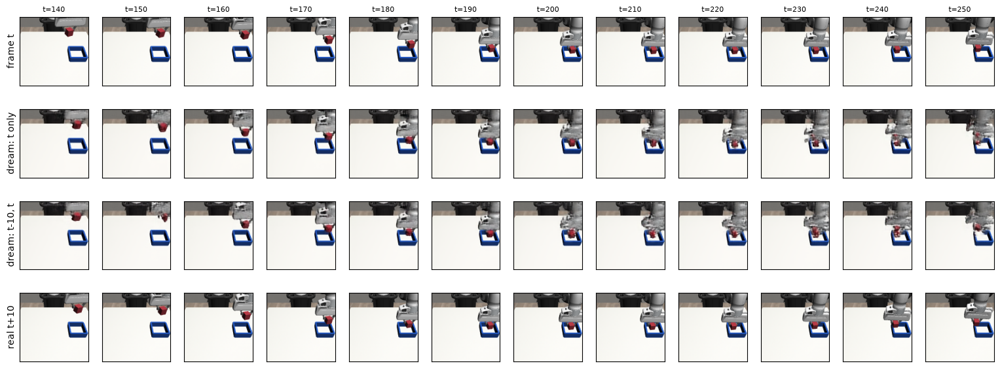

In [92]:
cols = [s for s in shots if 140 <= s[0] <= 250]
fig, axs = plt.subplots(4, len(cols), figsize=(1.6 * len(cols), 7))
for j, (t, now, dx, dp, real) in enumerate(cols):
    for i, img in enumerate([now, dx, dp, real]):
        axs[i, j].imshow((img.cpu().numpy().transpose(1, 2, 0) + 1) / 2)
        axs[i, j].set(xticks=[], yticks=[])
    axs[0, j].set_title(f't={t}', fontsize=8)
for ax, name in zip(axs[:, 0], ['frame t', 'dream: t only', 'dream: t-10, t', 'real t+10']):
    ax.set_ylabel(name)

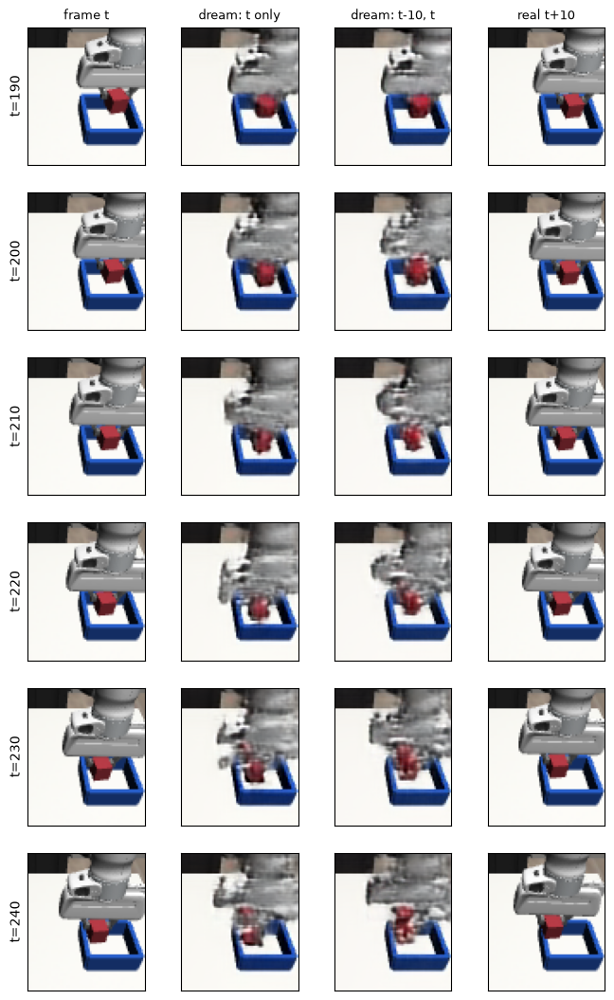

In [93]:
zoom = [s for s in shots if 190 <= s[0] <= 240]  # over the bin, cropped around it
fig, axs = plt.subplots(len(zoom), 4, figsize=(8, 2.2 * len(zoom)))
for row, (t, *imgs) in zip(axs, zoom):
    for ax, img in zip(row, imgs):
        ax.imshow((img.cpu().numpy().transpose(1, 2, 0)[15:95, 60:128] + 1) / 2)
        ax.set(xticks=[], yticks=[])
    row[0].set_ylabel(f't={t}')
for ax, name in zip(axs[0], ['frame t', 'dream: t only', 'dream: t-10, t', 'real t+10']):
    ax.set_title(name, fontsize=9)

## Step 14: longer context

Frames t-30, t-20, t-10 and t: enough to see that the arm has arrived over the bin and stopped.


In [100]:
run_p3 = train_video(predict='x', past=True, n_past=3)

 1000  train 0.0087   val 0.0083
 2000  train 0.0053   val 0.0064
 3000  train 0.0046   val 0.0055
 4000  train 0.0057   val 0.0049
 5000  train 0.0054   val 0.0044
 6000  train 0.0038   val 0.0042
 7000  train 0.0036   val 0.0039
 8000  train 0.0036   val 0.0038
 9000  train 0.0029   val 0.0037
10000  train 0.0033   val 0.0037


In [102]:
net_p3 = UNet(12).to(dev).eval()
net_p3.load_state_dict(run_p3['weights'])
s_tot, n_tot = 0, 0
for b in np.split(vr, 8):
    s, m = moving_mse(dream(net_p3, cond(b, True, 3), 'x'), frames(b), frames(b + K))
    s_tot, n_tot = s_tot + s, n_tot + m
print(f'x + 3 past frames: moving mse {s_tot / n_tot:.4f}   (1 past 0.0194, t only 0.0265)')

x + 3 past frames: moving mse 0.0173   (1 past 0.0194, t only 0.0265)


In [103]:
res_p3 = {seed: rollout(seed, net_p3, past=True, n_past=3) for seed in range(1000, 1020)}
print(
    f'x + 3 past frames: {sum(ok for ok, _, _ in res_p3.values())}/20   (1 past 9/20, t only 17/20)'
)
print('failed', {s: m for s, (ok, m, _) in res_p3.items() if not ok})

x + 3 past frames: 11/20   (1 past 9/20, t only 17/20)
failed {1001: 'wrong_target', 1003: 'wrong_target', 1004: 'wrong_target', 1006: 'wrong_target', 1007: 'wrong_target', 1010: 'wrong_target', 1011: 'dropped', 1012: 'wrong_target', 1018: 'wrong_target'}


In [104]:
imageio.mimsave(
    '../scratch/video_p3_seed1001.mp4', rollout_frames(1001, net_p3, past=True, n_past=3), fps=20
)  # wrong_target
Video('../scratch/video_p3_seed1001.mp4', embed=True, width=512)

seed 1001: 600 steps, success False, wrong_target


In [105]:
imageio.mimsave(
    '../scratch/video_p3_seed1011.mp4', rollout_frames(1011, net_p3, past=True, n_past=3), fps=20
)  # dropped
Video('../scratch/video_p3_seed1011.mp4', embed=True, width=512)

seed 1011: 600 steps, success False, dropped


In [106]:
ok_p3 = [s for s, (ok, _, _) in res_p3.items() if ok]
print(ok_p3)
imageio.mimsave(
    f'../scratch/video_p3_seed{ok_p3[0]}.mp4',
    rollout_frames(ok_p3[0], net_p3, past=True, n_past=3),
    fps=20,
)  # a success
Video(f'../scratch/video_p3_seed{ok_p3[0]}.mp4', embed=True, width=512)

[1000, 1002, 1005, 1008, 1009, 1013, 1014, 1015, 1016, 1017, 1019]
seed 1000: 542 steps, success True, none


## Step 15: up-weight the moments where motion changes

For each training row: how far the next 10 steps' joint motion is from continuing the last 10 steps'
(joints in std units, gripper included). Large at the stop over the bin, the release, the turns.


In [107]:
back = np.maximum(tr - K, first[tr])
z = (state - state[tr].mean(0)) / state[tr].std(0)
change = np.linalg.norm((z[tr + K] - z[tr]) - (z[tr] - z[back]), axis=1)  # [len(tr)]
print(np.percentile(change, [10, 50, 90, 99]).round(2))

[0.24 0.63 2.09 2.65]


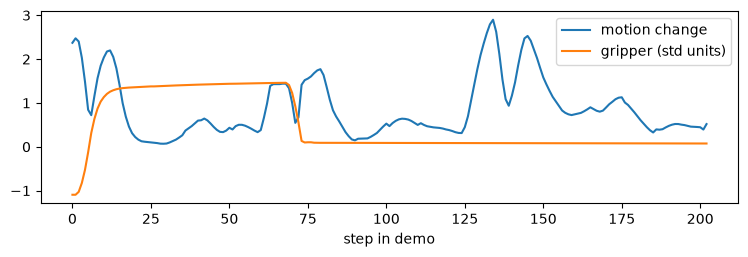

In [108]:
d = tr[episode[tr] == episode[tr[0]]]  # one training demo
fig, ax = plt.subplots(figsize=(9, 2.5))
ax.plot(d - d[0], change[np.isin(tr, d)], label='motion change')
ax.plot(d - d[0], z[d, 7], label='gripper (std units)')
ax.set_xlabel('step in demo')
ax.legend()

In [111]:
run_p3w = train_video(predict='x', past=True, n_past=3, upweight=3.0)

 1000  train 0.0086   val 0.0089
 2000  train 0.0050   val 0.0066
 3000  train 0.0042   val 0.0057
 4000  train 0.0046   val 0.0051
 5000  train 0.0045   val 0.0047
 6000  train 0.0039   val 0.0044
 7000  train 0.0037   val 0.0041
 8000  train 0.0033   val 0.0039
 9000  train 0.0032   val 0.0038
10000  train 0.0030   val 0.0038


In [114]:
net_p3w = UNet(12).to(dev).eval()
net_p3w.load_state_dict(run_p3w['weights'])
s_tot, n_tot = 0, 0
for b in np.split(vr, 8):
    s, m = moving_mse(dream(net_p3w, cond(b, True, 3), 'x'), frames(b), frames(b + K))
    s_tot, n_tot = s_tot + s, n_tot + m
print(f'3 past + upweight: moving mse {s_tot / n_tot:.4f}   (3 past 0.0173, t only 0.0265)')

3 past + upweight: moving mse 0.0183   (3 past 0.0173, t only 0.0265)


In [115]:
evals = {
    't only': {seed: rollout(seed, net_x) for seed in range(1000, 1020)},
    '3 past': {seed: rollout(seed, net_p3, past=True, n_past=3) for seed in range(1000, 1020)},
    '3 past + upweight': {
        seed: rollout(seed, net_p3w, past=True, n_past=3) for seed in range(1000, 1020)
    },
}
for name, res_n in evals.items():
    steps = [n for ok, _, n in res_n.values() if ok]
    print(
        f'{name:18s} {len(steps)}/20   success steps median {np.median(steps):.0f}, max {max(steps)}   '
        f'failed {[s for s, (ok, _, _) in res_n.items() if not ok]}'
    )

t only             17/20   success steps median 215, max 247   failed [1001, 1002, 1016]
3 past             11/20   success steps median 212, max 542   failed [1001, 1003, 1004, 1006, 1007, 1010, 1011, 1012, 1018]
3 past + upweight  12/20   success steps median 241, max 552   failed [1001, 1005, 1007, 1008, 1010, 1012, 1015, 1017]


## Step 16: the IDM reads the past too

Same encoder; keypoints of frames t-30, t-20, t-10 join (now, dream, dream - now, joints).
Trained on real frames, as `idm.ipynb`'s. Val on the 512 `vr` rows: arm error, gripper right
(`idm.ipynb`'s IDM: arm 0.00003, gripper 99.5%).


In [143]:
from frozendict import frozendict
from idm_parts import IDM


@cache
def train_idm_past(
    steps: int = 10000, B: int = 64, lr: float = 1e-3, seed: int = 0, n_past: int = 3, k: int = K,
    wrist: bool = False,
):
    # an IDM on k-step gaps that also reads n_past earlier frames, k apart -> weights (CPU), log rows
    # [step, train loss, val arm error, val gripper right]; wrist: also read the wrist camera (step 18)
    gap_ok = np.flatnonzero(episode[:-k] == episode[k:])  # rows t with t+k in the same demo
    in_val = np.isin(episode[gap_ok], val)
    vr_k = np.random.default_rng(1).choice(gap_ok[in_val], 512, replace=False)  # = vr for k=10
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = IDM(k, n_past, wrist).to(dev)
    cams = [None, wcam] if wrist else [None]  # None = top
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    va = action[vr_k[:, None] + np.arange(k)]

    def view(b, n):
        # rows -> [B, n + 1, 3 per camera, 128, 128] in [0, 1]: n earlier frames k apart, then frame t
        out = [(cond(b, n > 0, n, k, cam) + 1).unflatten(1, (n + 1, 3)) / 2 for cam in cams]
        return torch.cat(out, 2)

    def read(b):
        # rows -> the net's actions [B, k, 8] in std units, from real frames
        c = view(b, n_past)
        joints = torch.tensor((state[b] - s_mean) / s_std, device=dev)
        return net(c[:, -1], view(b + k, 0)[:, 0], joints, list(c[:, :-1].unbind(1)))

    log = []
    for step in range(1, steps + 1):
        b = rng.choice(gap_ok[~in_val], B)
        target = torch.tensor((action[b[:, None] + np.arange(k)] - a_mean) / a_std, device=dev)
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss = (read(b).float() - target).square().mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step % 1000 == 0:
            with torch.no_grad():
                pred = torch.cat([read(c).float() for c in np.split(vr_k, 8)]).cpu().numpy()
            pred = pred * a_std + a_mean
            arm = ((pred - va)[..., :7] ** 2).mean()
            grip = ((pred[..., 7] > 0.5) == (va[..., 7] > 0.5)).mean()
            log.append([step, loss.item(), arm, grip])
            print(
                f'{step:5d}  train {loss.item():.4f}   val arm {arm:.5f}  gripper right {grip:.1%}',
                flush=True,
            )
    weights = {name: w.cpu() for name, w in net.state_dict().items()}
    return frozendict(weights=weights, log=np.array(log))

train_idm_past: not cached, will compute


In [132]:
run_ip = train_idm_past()

train_idm_past: result copied by keep=True from older code (cell e715a9d01861)
 1000  train 0.0071   val arm 0.00012  gripper right 99.2%
 2000  train 0.0071   val arm 0.00007  gripper right 99.5%
 3000  train 0.0067   val arm 0.00006  gripper right 99.6%
 4000  train 0.0038   val arm 0.00005  gripper right 99.5%
 5000  train 0.0043   val arm 0.00004  gripper right 99.5%
 6000  train 0.0031   val arm 0.00004  gripper right 99.6%
 7000  train 0.0037   val arm 0.00004  gripper right 99.5%
 8000  train 0.0024   val arm 0.00003  gripper right 99.6%
 9000  train 0.0021   val arm 0.00003  gripper right 99.7%
10000  train 0.0024   val arm 0.00003  gripper right 99.6%


Oracle check first (as `idm.ipynb` step 11): the expert's real future instead of a dream, so only
the IDM is tested. `idm.ipynb`'s IDM: 19/20.


In [158]:
from idm_parts import imagine

from dream_robot.sims.robosuite.tasks.pick_place_cube.expert import ExpertPolicy

expert = ExpertPolicy(env)


@torch.no_grad()
def rollout_oracle(seed, reader, film=None, trace=None):
    # one episode, the IDM reading the expert's real future (sim rewound) -> (success, failure mode, steps)
    # film: a list to append every step's [real | expert's future] per camera, side by side, 2x upscaled
    # trace: a list to append (t, expert phase, hand xyz, bin centre xyz) at every dream point (diagnosis)
    obs = env.reset(seed=seed)
    expert.reset()
    cams = ['top', 'wrist'] if getattr(reader, 'wrist', False) else ['top']
    seen = []  # [1, 3 per camera, 128, 128] in [0, 1]
    for t in range(600):
        seen.append((torch.cat([to_t(obs.images[c]) for c in cams], 1) + 1) / 2)
        if t % reader.k == 0:
            if trace is not None:
                hand = env.mujoco[1].site('gripper0_right_grip_site').xpos.copy()
                trace.append((t, expert.phase, hand, np.array(env.bin_center)))
            ahead = imagine(env, expert, obs, reader.k)
            fut_imgs = [ahead.images[c] for c in cams]
            fut = (torch.cat([to_t(ahead.images[c]) for c in cams], 1) + 1) / 2
            past = [seen[max(t - j * reader.k, 0)] for j in range(reader.n_past, 0, -1)]
            joints = torch.tensor((obs.state - s_mean) / s_std, device=dev)[None]
            acts = reader(seen[t], fut, joints, past)[0].cpu().numpy() * a_std + a_mean
            acts[:, 7] = acts[:, 7].clip(0, 1)
        if film is not None:
            pairs = [img for c, f in zip(cams, fut_imgs) for img in (obs.images[c], f)]
            film.append(np.concatenate(pairs, 1).repeat(2, 0).repeat(2, 1))
        expert(obs)  # the shadow expert sees the real step
        res = env.step(acts[t % reader.k])
        obs = res.observation
        if res.terminated or res.truncated:
            break
    return res.success, str(res.failure_mode), t + 1

In [123]:
res_o = {seed: rollout_oracle(seed, idm) for seed in range(1000, 1020)}
print(f'oracle, idm.ipynb IDM: {sum(ok for ok, _, _ in res_o.values())}/20   (idm.ipynb: 19/20)')

oracle, idm.ipynb IDM: 20/20   (idm.ipynb: 19/20)


In [126]:
idm_p = IDM(K, 3).to(dev).eval()
idm_p.load_state_dict(run_ip['weights'])
res_op = {seed: rollout_oracle(seed, idm_p) for seed in range(1000, 1020)}
print(
    f'oracle, past IDM: {sum(ok for ok, _, _ in res_op.values())}/20   '
    f'failed {[s for s, (ok, _, _) in res_op.items() if not ok]}'
)

oracle, past IDM: 11/20   failed [1000, 1007, 1008, 1011, 1012, 1013, 1014, 1016, 1017]


In [128]:
film = []
print(rollout_oracle(1000, idm_p, film))
imageio.mimsave('../scratch/oracle_pastidm_seed1000.mp4', film, fps=20)
Video('../scratch/oracle_pastidm_seed1000.mp4', embed=True, width=512)

(False, 'wrong_target', 600)


In [129]:
film = []
print(rollout_oracle(1007, idm_p, film))
imageio.mimsave('../scratch/oracle_pastidm_seed1007.mp4', film, fps=20)
Video('../scratch/oracle_pastidm_seed1007.mp4', embed=True, width=512)

(False, 'wrong_target', 600)


## Step 17: k=16

Dream (here: the expert's future) 16 steps ahead: the fingers are visibly open at the release.
Does the stronger cue beat the past? Past frames 16 apart. `idm.ipynb`: k=16, no past 14/20.


In [135]:
runs_16 = {n: train_idm_past(n_past=n, k=16) for n in [0, 3]}

 1000  train 0.0093   val arm 0.00013  gripper right 99.4%
 2000  train 0.0083   val arm 0.00008  gripper right 99.6%
 3000  train 0.0065   val arm 0.00006  gripper right 99.6%
 4000  train 0.0040   val arm 0.00005  gripper right 99.6%
 5000  train 0.0054   val arm 0.00005  gripper right 99.7%
 6000  train 0.0027   val arm 0.00004  gripper right 99.6%
 7000  train 0.0038   val arm 0.00004  gripper right 99.6%
 8000  train 0.0027   val arm 0.00004  gripper right 99.6%
 9000  train 0.0030   val arm 0.00004  gripper right 99.6%
10000  train 0.0033   val arm 0.00004  gripper right 99.6%
 1000  train 0.0092   val arm 0.00014  gripper right 99.3%
 2000  train 0.0082   val arm 0.00008  gripper right 99.6%
 3000  train 0.0067   val arm 0.00006  gripper right 99.7%
 4000  train 0.0042   val arm 0.00005  gripper right 99.7%
 5000  train 0.0054   val arm 0.00004  gripper right 99.8%
 6000  train 0.0026   val arm 0.00004  gripper right 99.7%
 7000  train 0.0035   val arm 0.00004  gripper right 99.

In [136]:
for n, run_n in runs_16.items():
    idm_n = IDM(16, n).to(dev).eval()
    idm_n.load_state_dict(run_n['weights'])
    res_n = {seed: rollout_oracle(seed, idm_n) for seed in range(1000, 1020)}
    print(
        f'oracle, k=16, {n} past: {sum(ok for ok, _, _ in res_n.values())}/20   '
        f'failed {[s for s, (ok, _, _) in res_n.items() if not ok]}'
    )

oracle, k=16, 0 past: 16/20   failed [1009, 1010, 1012, 1015]
oracle, k=16, 3 past: 15/20   failed [1003, 1008, 1009, 1010, 1016]


In [137]:
idm_16p = IDM(16, 3).to(dev).eval()
idm_16p.load_state_dict(runs_16[3]['weights'])

<All keys matched successfully>

In [138]:
film = []
print(rollout_oracle(1003, idm_16p, film))
imageio.mimsave('../scratch/oracle_16p_seed1003.mp4', film, fps=20)
Video('../scratch/oracle_16p_seed1003.mp4', embed=True, width=512)

(False, 'wrong_target', 600)


In [139]:
film = []
print(rollout_oracle(1009, idm_16p, film))
imageio.mimsave('../scratch/oracle_16p_seed1009.mp4', film, fps=20)
Video('../scratch/oracle_16p_seed1009.mp4', embed=True, width=512)

(False, 'dropped', 600)


## Step 18: the wrist camera

The fingers fill the wrist view, so the release is many pixels, not 3-4. The IDM reads both views,
each with its own encoder. Oracle loop, k=10: without and with 3 past frames.


In [145]:
wcam = np.load(f'../cache/lam/{NAME}_wrist.npy')  # [N, 3, 128, 128] uint8, same rows as top
print(wcam.shape)

(21295, 3, 128, 128)


Text(0, 0.5, 'wrist')

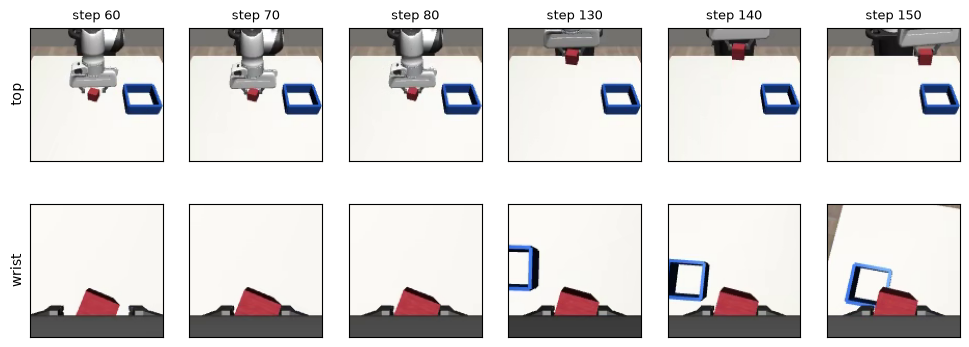

In [146]:
t0 = np.flatnonzero(episode == 31)[0]
show = [60, 70, 80, 130, 140, 150]  # around the grasp and the release
fig, axs = plt.subplots(2, len(show), figsize=(2 * len(show), 4.2))
for j, s in enumerate(show):
    for ax, cam in zip(axs[:, j], [top, wcam]):
        ax.imshow(cam[t0 + s].transpose(1, 2, 0))
        ax.set(xticks=[], yticks=[])
    axs[0, j].set_title(f'step {s}', fontsize=9)
axs[0, 0].set_ylabel('top')
axs[1, 0].set_ylabel('wrist')

In [147]:
runs_w = {n: train_idm_past(n_past=n, wrist=True) for n in [0, 3]}

 1000  train 0.0073   val arm 0.00010  gripper right 99.4%
 2000  train 0.0062   val arm 0.00007  gripper right 99.6%
 3000  train 0.0051   val arm 0.00005  gripper right 99.7%
 4000  train 0.0037   val arm 0.00005  gripper right 99.7%
 5000  train 0.0037   val arm 0.00004  gripper right 99.7%
 6000  train 0.0025   val arm 0.00003  gripper right 99.7%
 7000  train 0.0026   val arm 0.00003  gripper right 99.7%
 8000  train 0.0019   val arm 0.00003  gripper right 99.7%
 9000  train 0.0017   val arm 0.00003  gripper right 99.7%
10000  train 0.0019   val arm 0.00003  gripper right 99.7%
 1000  train 0.0068   val arm 0.00011  gripper right 99.6%
 2000  train 0.0059   val arm 0.00007  gripper right 99.6%
 3000  train 0.0053   val arm 0.00005  gripper right 99.7%
 4000  train 0.0034   val arm 0.00004  gripper right 99.8%
 5000  train 0.0034   val arm 0.00004  gripper right 99.8%
 6000  train 0.0024   val arm 0.00004  gripper right 99.8%
 7000  train 0.0024   val arm 0.00003  gripper right 99.

In [148]:
for n, run_n in runs_w.items():
    idm_n = IDM(K, n, wrist=True).to(dev).eval()
    idm_n.load_state_dict(run_n['weights'])
    res_n = {seed: rollout_oracle(seed, idm_n) for seed in range(1000, 1020)}
    print(
        f'oracle, top + wrist, {n} past: {sum(ok for ok, _, _ in res_n.values())}/20   '
        f'failed {[s for s, (ok, _, _) in res_n.items() if not ok]}'
    )

oracle, top + wrist, 0 past: 19/20   failed [1009]
oracle, top + wrist, 3 past: 12/20   failed [1000, 1002, 1003, 1006, 1009, 1010, 1011, 1014]


Failures of top + wrist with 3 past: [top real | top future | wrist real | wrist future].


In [152]:
idm_w3 = IDM(K, 3, wrist=True).to(dev).eval()
idm_w3.load_state_dict(runs_w[3]['weights'])

<All keys matched successfully>

In [153]:
film = []
print(rollout_oracle(1000, idm_w3, film))
imageio.mimsave('../scratch/oracle_w3_seed1000.mp4', film, fps=20)
Video('../scratch/oracle_w3_seed1000.mp4', embed=True, width=1024)

(False, 'wrong_target', 600)


In [154]:
film = []
print(rollout_oracle(1002, idm_w3, film))
imageio.mimsave('../scratch/oracle_w3_seed1002.mp4', film, fps=20)
Video('../scratch/oracle_w3_seed1002.mp4', embed=True, width=1024)

(False, 'wrong_target', 600)


In [155]:
idm_w0 = IDM(K, 0, wrist=True).to(dev).eval()
idm_w0.load_state_dict(runs_w[0]['weights'])

<All keys matched successfully>

In [157]:
film = []
print(rollout_oracle(1009, idm_w0, film))  # top + wrist, no past: its one failure
imageio.mimsave('../scratch/oracle_w0_seed1009.mp4', film, fps=20)
Video('../scratch/oracle_w0_seed1009.mp4', embed=True, width=1024)

(False, 'wrong_target', 600)


Why 1009? The expert's phase and the hand's distance to its target over the episode (sim state, diagnosis only).
The expert lowers to 8.5 cm above the bin centre and advances to release within 1.5 cm.


In [159]:
trace = []
print(rollout_oracle(1009, idm_w0, trace=trace))
for t, phase, hand, bin_c in trace[::3]:
    off = hand - bin_c
    print(f'{t:3d} {phase:8s} hand - bin centre: x {off[0]:+.3f} y {off[1]:+.3f} z {off[2]:+.3f}')

(False, 'wrong_target', 600)
  0 approach hand - bin centre: x -0.067 y -0.202 z +0.239
 30 approach hand - bin centre: x +0.011 y -0.230 z +0.175
 60 descend  hand - bin centre: x +0.018 y -0.231 z +0.068
 90 lift     hand - bin centre: x +0.010 y -0.229 z +0.041
120 lift     hand - bin centre: x -0.086 y -0.225 z +0.099
150 carry    hand - bin centre: x +0.009 y -0.227 z +0.271
180 carry    hand - bin centre: x +0.007 y -0.053 z +0.245
210 carry    hand - bin centre: x +0.008 y -0.004 z +0.196
240 carry    hand - bin centre: x +0.009 y -0.009 z +0.179
270 carry    hand - bin centre: x +0.009 y -0.008 z +0.179
300 carry    hand - bin centre: x +0.007 y -0.007 z +0.175
330 carry    hand - bin centre: x +0.006 y -0.007 z +0.175
360 carry    hand - bin centre: x +0.004 y -0.011 z +0.173
390 carry    hand - bin centre: x +0.003 y -0.016 z +0.171
420 carry    hand - bin centre: x +0.002 y -0.026 z +0.168
450 carry    hand - bin centre: x -0.002 y -0.033 z +0.165
480 carry    hand - bin cen

## Step 20: the video model dreams top + wrist

Condition [top t, wrist t], dream [top t+10, wrist t+10], clean-frame prediction, no past.
Read by the top + wrist IDM (oracle 19/20). Against: top-only video model + top IDM, 17/20.


In [165]:
run_w2 = train_video(predict='x', wrist=True)

 1000  train 0.0181   val 0.0141
 2000  train 0.0120   val 0.0111
 3000  train 0.0085   val 0.0096
 4000  train 0.0066   val 0.0084
 5000  train 0.0068   val 0.0078
 6000  train 0.0070   val 0.0073
 7000  train 0.0069   val 0.0069
 8000  train 0.0086   val 0.0066
 9000  train 0.0066   val 0.0065
10000  train 0.0071   val 0.0064


In [166]:
net_w = UNet(6, 6).to(dev).eval()
net_w.load_state_dict(run_w2['weights'])
tot = {'top': [0, 0], 'wrist': [0, 0]}
for b in np.split(vr, 8):
    both_now = torch.cat([frames(b), frames(b, wcam)], 1)
    d = dream(net_w, both_now, 'x')
    for j, (name, cam) in enumerate([('top', None), ('wrist', wcam)]):
        s, m = moving_mse(d[:, 3 * j : 3 * j + 3], frames(b, cam), frames(b + K, cam))
        tot[name][0] += s
        tot[name][1] += m
for name, (s, m) in tot.items():
    print(f'{name:5s} moving mse {s / m:.4f}')
print('(top-only model, top: 0.0265)')

top   moving mse 0.0326
wrist moving mse 0.0657
(top-only model, top: 0.0265)


In [167]:
res_w = {seed: rollout(seed, net_w, reader=idm_w0, wrist=True) for seed in range(1000, 1020)}
steps = [n for ok, _, n in res_w.values() if ok]
print(
    f'top + wrist dreams, top + wrist IDM: {len(steps)}/20   success steps median {np.median(steps):.0f}, '
    f'max {max(steps)}   failed {[s for s, (ok, _, _) in res_w.items() if not ok]}   (top only: 17/20)'
)

top + wrist dreams, top + wrist IDM: 6/20   success steps median 206, max 298   failed [1000, 1001, 1002, 1003, 1004, 1008, 1009, 1010, 1011, 1013, 1014, 1017, 1018, 1019]   (top only: 17/20)


In [169]:
res_wt = {seed: rollout(seed, net_w, reader=idm, wrist=True) for seed in range(1000, 1020)}
print(
    f'top + wrist dreams, top-only IDM on the top half: {sum(ok for ok, _, _ in res_wt.values())}/20   '
    f'failed {[s for s, (ok, _, _) in res_wt.items() if not ok]}   (wrist IDM 6/20, top-only pair 17/20)'
)

top + wrist dreams, top-only IDM on the top half: 5/20   failed [1001, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010, 1011, 1012, 1014, 1017, 1018, 1019]   (wrist IDM 6/20, top-only pair 17/20)


In [172]:
imageio.mimsave(
    '../scratch/video_w_seed1000.mp4',
    rollout_frames(1000, net_w, reader=idm_w0, wrist=True),
    fps=20,
)
Video('../scratch/video_w_seed1000.mp4', embed=True, width=1024)

seed 1000: 600 steps, success False, wrong_target


In [173]:
imageio.mimsave(
    '../scratch/video_w_seed1001.mp4',
    rollout_frames(1001, net_w, reader=idm_w0, wrist=True),
    fps=20,
)
Video('../scratch/video_w_seed1001.mp4', embed=True, width=1024)

seed 1001: 600 steps, success False, no_grasp


In [174]:
imageio.mimsave(
    '../scratch/video_w_seed1005.mp4',
    rollout_frames(1005, net_w, reader=idm_w0, wrist=True),
    fps=20,
)  # a success
Video('../scratch/video_w_seed1005.mp4', embed=True, width=1024)

seed 1005: 231 steps, success True, none
